<span style="color:gold">

## 1. Required Modules

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# colours to use for visualizations
viz_colour = '#881946'

<span style="color:gold">

## 2. Import Both Datasets

In [7]:
health_data = pd.read_excel('ehealth-kenya-facilities-download-21102015.xls')
sc_data = pd.read_csv('kenya-population-by-sub-county.csv')

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero


<span style="color:gold">

## 3. Health Data Pre-processing

- Filter Nairobi county data
- Remove special characters from text
- In order to match it with census data, add a `Region` column and map the consituencies as follows:

| Constituency       | Region     |
|--------------------|------------|
| DAGORETTI NORTH    | Dagoretti  |
| DAGORETTI SOUTH    | Dagoretti  |
| EMBAKASI CENTRAL   | Embakasi   |
| EMBAKASI EAST      | Embakasi   |
| EMBAKASI NORTH     | Embakasi   |
| EMBAKASI SOUTH     | Embakasi   |
| EMBAKASI WEST      | Embakasi   |
| KAMUKUNJI          | Kamukunji  |
| KASARANI           | Kasarani   |
| KIBRA              | Kibra      |
| LANGATA            | Langata    |
| MAKADARA           | Makadara   |
| MATHARE            | Mathare    |
| ROYSAMBU           | Kasarani   |
| RUARAKA            | Kasarani   |
| STAREHE            | Starehe    |
| WESTLANDS          | Westlands  |

- Confirm that data types are consistent

In [8]:
health_data.columns

Index(['Facility Code', 'Facility Name', 'Province', 'County', 'District',
       'Division', 'Type', 'Owner', 'Location', 'Sub Location',
       'Description of Location', 'Constituency', 'Nearest Town', 'Beds',
       'Cots', 'Official Landline', 'Official Fax', 'Official Mobile',
       'Official Email', 'Official Address', 'Official Alternate No', 'Town',
       'Post Code', 'In Charge', 'Job Title of in Charge', 'Open 24 Hours',
       'Open Weekends', 'Operational Status', 'ANC', 'ART', 'BEOC', 'BLOOD',
       'CAES SEC', 'CEOC', 'C-IMCI', 'EPI', 'FP', 'GROWM', 'HBC', 'HCT', 'IPD',
       'OPD', 'OUTREACH', 'PMTCT', 'RAD/XRAY', 'RHTC/RHDC', 'TB DIAG',
       'TB LABS', 'TB TREAT', 'YOUTH'],
      dtype='object')

In [9]:
# Filter Nairobi county only
health_data = health_data[health_data['County'] == 'Nairobi']
health_data.shape

(942, 50)

In [10]:
# Removing special characters
health_data['Constituency'] = health_data['Constituency'].map(lambda x: x.replace("'", ""))

In [11]:
# Introducing a regions column

# Source: https://en.wikipedia.org/wiki/Roysambu_Constituency
# Source: https://en.wikipedia.org/wiki/Ruaraka_Constituency

health_data['Region'] = [(i in ('ROYSAMBU', 'RUARAKA')) * 'KASARANI' or i.split(' ')[0] for i in health_data['Constituency']]
health_data['Region'] = health_data['Region'].map(str.capitalize)

assert len(health_data['Region'].unique()) == 10 # We'll be working with 10 regions

In [12]:
# Checking data-type consistency
{col: health_data[col].dtypes for col in health_data.columns}

{'Facility Code': dtype('int64'),
 'Facility Name': dtype('O'),
 'Province': dtype('O'),
 'County': dtype('O'),
 'District': dtype('O'),
 'Division': dtype('O'),
 'Type': dtype('O'),
 'Owner': dtype('O'),
 'Location': dtype('O'),
 'Sub Location': dtype('O'),
 'Description of Location': dtype('O'),
 'Constituency': dtype('O'),
 'Nearest Town': dtype('O'),
 'Beds': dtype('float64'),
 'Cots': dtype('float64'),
 'Official Landline': dtype('O'),
 'Official Fax': dtype('O'),
 'Official Mobile': dtype('O'),
 'Official Email': dtype('O'),
 'Official Address': dtype('O'),
 'Official Alternate No': dtype('float64'),
 'Town': dtype('O'),
 'Post Code': dtype('O'),
 'In Charge': dtype('O'),
 'Job Title of in Charge': dtype('O'),
 'Open 24 Hours': dtype('O'),
 'Open Weekends': dtype('O'),
 'Operational Status': dtype('O'),
 'ANC': dtype('float64'),
 'ART': dtype('O'),
 'BEOC': dtype('float64'),
 'BLOOD': dtype('float64'),
 'CAES SEC': dtype('float64'),
 'CEOC': dtype('float64'),
 'C-IMCI': dtype('O'

<span style="color:gold">

## 4. Census Data Pre-processing

- There are only 5 columns, delete the rest of the table containing no data
- Column names are found in row 5. Since the data is on subcounty-level, rename the first column from `name` to `Subcounty`
- Filter Nairobi county data - this is found on row 388 to the end
- Remove leading and trailing spaces
- Remove special characters from text data
- Change population data stored as string to `float`
- As with the health data, introduce `Region` column and map as follows:

| Subcounty   | Region     |
|:------------|:-----------|
| Dagoretti   | Dagoretti  |
| Embakasi    | Embakasi   |
| Kamukunji   | Kamukunji  |
| Kasarani    | Kasarani   |
| Kibra       | Kibra      |
| Langata     | Langata    |
| Makadara    | Makadara   |
| Mathare     | Mathare    |
| Njiru       | Kasarani   |
| Starehe     | Starehe    |
| Westlands   | Westlands  |


In [13]:
sc_data.head(10)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,Distribution of Population by Sex and Sub-County,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Source: 2019 Kenya Population and Housing Cens...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,https://www.knbs.or.ke/?wpdmpro=2019-kenya-pop...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Population, Male, Female, Intersex, Sub-county...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,name,Male,Female,Intersex,Total,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Kenya,23548056,24014716,1524,47564296,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Mombasa,610257,598046,30,1208333,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Changamwe,68761,63121,NaN,131882,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Jomvu,83002,80410,3,163415,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
sc_data = sc_data[sc_data.columns[:5]] # Delete empty columns

col_names = ['Subcounty'] + list(sc_data.loc[5][1:].values) # pick the column names from row 5 and rename the first one to Subcounty
sc_data.columns = col_names

sc_data = sc_data.loc[388:] # Filter Nairobi county data
sc_data.index = range(sc_data.shape[0]) # reset index
sc_data = sc_data.map(str.strip) # Remove leading and trailing spaces
sc_data = sc_data.map(lambda x: x.replace("'", "")) # remove special characters

sc_data.update(sc_data[sc_data.columns[1:]].map(float)) # convert population data string to float

In [15]:
# Introducing region column
sc_data['Region'] = sc_data['Subcounty'].map(lambda x: x.replace('Njiru', 'Kasarani'))
sc_data = sc_data.groupby('Region').sum().reset_index()

sc_data

,Region,Subcounty,Male,Female,Intersex,Total
0,Dagoretti,Dagoretti,217651.0,216526.0,31.0,434208.0
1,Embakasi,Embakasi,492476.0,496270.0,62.0,988808.0
2,Kamukunji,Kamukunji,136670.0,131599.0,7.0,268276.0
3,Kasarani,KasaraniNjiru,688876.0,718194.0,68.0,1407138.0
4,Kibra,Kibra,94199.0,91569.0,9.0,185777.0
5,Langata,Langata,96698.0,100774.0,17.0,197489.0
6,Makadara,Makadara,96369.0,93157.0,10.0,189536.0
7,Mathare,Mathare,106522.0,100028.0,14.0,206564.0
8,Starehe,Starehe,109173.0,101238.0,12.0,210423.0
9,Westlands,Westlands,153818.0,155021.0,15.0,308854.0


# ANALYSIS

<span style="color:gold">

## 5. Identify Non-operational Facilities

In [16]:
health_data['Operational Status'].value_counts()

,count
Operational Status,
Operational,917
Not-Operational,19
Pending Opening,6


- There are 19 non-operationl facilities and 6 pending opening
- Present this in a table as well as a list of those not in operation for action by the county

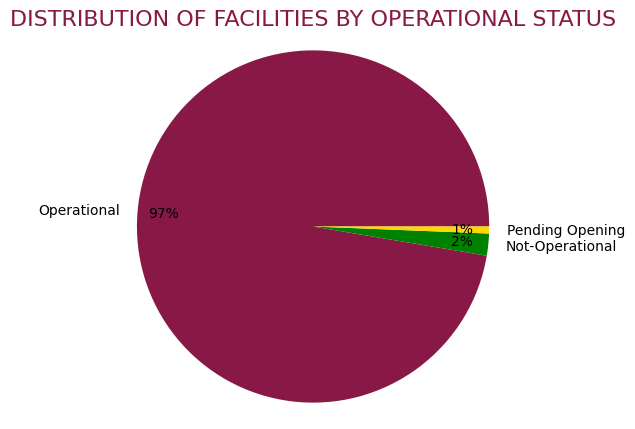

In [17]:
status_counts = health_data['Operational Status'].value_counts()

labels = status_counts.index
sizes = status_counts.values
colors = [viz_colour, 'green', 'gold']

plt.figure(figsize=(5,5))
plt.pie(sizes, labels=labels, autopct='%1.0f%%', pctdistance=0.85, colors=colors)
plt.title('DISTRIBUTION OF FACILITIES BY OPERATIONAL STATUS', fontsize=16, color=viz_colour)
plt.axis('equal')
plt.savefig('chart1.png', bbox_inches='tight')
plt.show()

In [18]:
# List of non-operational facilities
# Help re-open these. Especially Our Lady of Lourdes Mwea Hospital which already has beds and cots (IP) and operates 24-hours
health_data[health_data['Operational Status'] == 'Not-Operational'][
    ['Facility Name', 'Region', 'Location', 'Beds', 'Cots', 'Open 24 Hours', 'Open Weekends']].sort_values(['Region', 'Location'])

,Facility Name,Region,Location,Beds,Cots,Open 24 Hours,Open Weekends
2128,Kinga Medical Clinic (Dandora),Embakasi,Dandora,0.0,0.0,N,Y
5220,East Medical Clinic,Embakasi,Dandora,0.0,0.0,N,Y
8299,Our Lady of Lourdes Mwea Hospital,Embakasi,Kayole,50.0,20.0,Y,Y
9320,St Ann's Clinic,Embakasi,Kayole,0.0,0.0,N,N
2919,Mmak Embakasi Stand Alone VCT,Embakasi,Mukuru,0.0,0.0,NaN,NaN
5605,Darushif Medical Clinic,Embakasi,Umoja,0.0,0.0,N,N
9282,Special Provision Clinic,Embakasi,Umoja,0.0,0.0,Y,Y
5033,Imani Medical Centre,Kasarani,Githurai,0.0,0.0,N,Y
6350,Christian Aid Dispensary,Kasarani,Githurai,0.0,0.0,N,N
8763,Ronil Medical Clinic (Githurai),Kasarani,Githurai,0.0,0.0,N,N


In [19]:
# List of facilities pending opening - Help open these. They are all OP i.e. no beds/cots
health_data[health_data['Operational Status'] == 'Pending Opening'][
    ['Facility Name', 'Region', 'Location', 'Beds', 'Cots', 'Open 24 Hours', 'Open Weekends']].sort_values(['Region', 'Location'])

,Facility Name,Region,Location,Beds,Cots,Open 24 Hours,Open Weekends
8381,PCEA Silanga Church VCT,Kibra,Laini Saba,0.0,0.0,N,N
8015,Nyumba Kubwa Community Clinic(Darajani),Kibra,Makina,0.0,0.0,N,N
4939,Gatwekera B(Olympic),Kibra,Olympic,0.0,0.0,N,N
6205,Bar Hostess Empowerment and Support Programme ...,Makadara,Makongeni,0.0,0.0,N,N
2637,Medical Link Integrated Health Program,Makadara,Viwandani,0.0,0.0,N,Y
8980,Sasa Centre (Westlands),Westlands,Kangemi,0.0,0.0,N,Y


In [20]:
# FROM NOW ON, WE WORK WITH ONLY THE OPERATIONAL FACILITIES
health_data = health_data[health_data['Operational Status'] == 'Operational']

<span style="color:gold">

## 6. Insights tied to SDG 3

<span style="color:orange">

### SDG Target 3.8 - Universal Health Coverage

Under this, we'll look at:
- Types of facilities available
- Number of facilities per capita per region
- Hospital access: Hospital beds per capita
- Number of IPD and HBC services per capita per region - regions that are below average need boosting

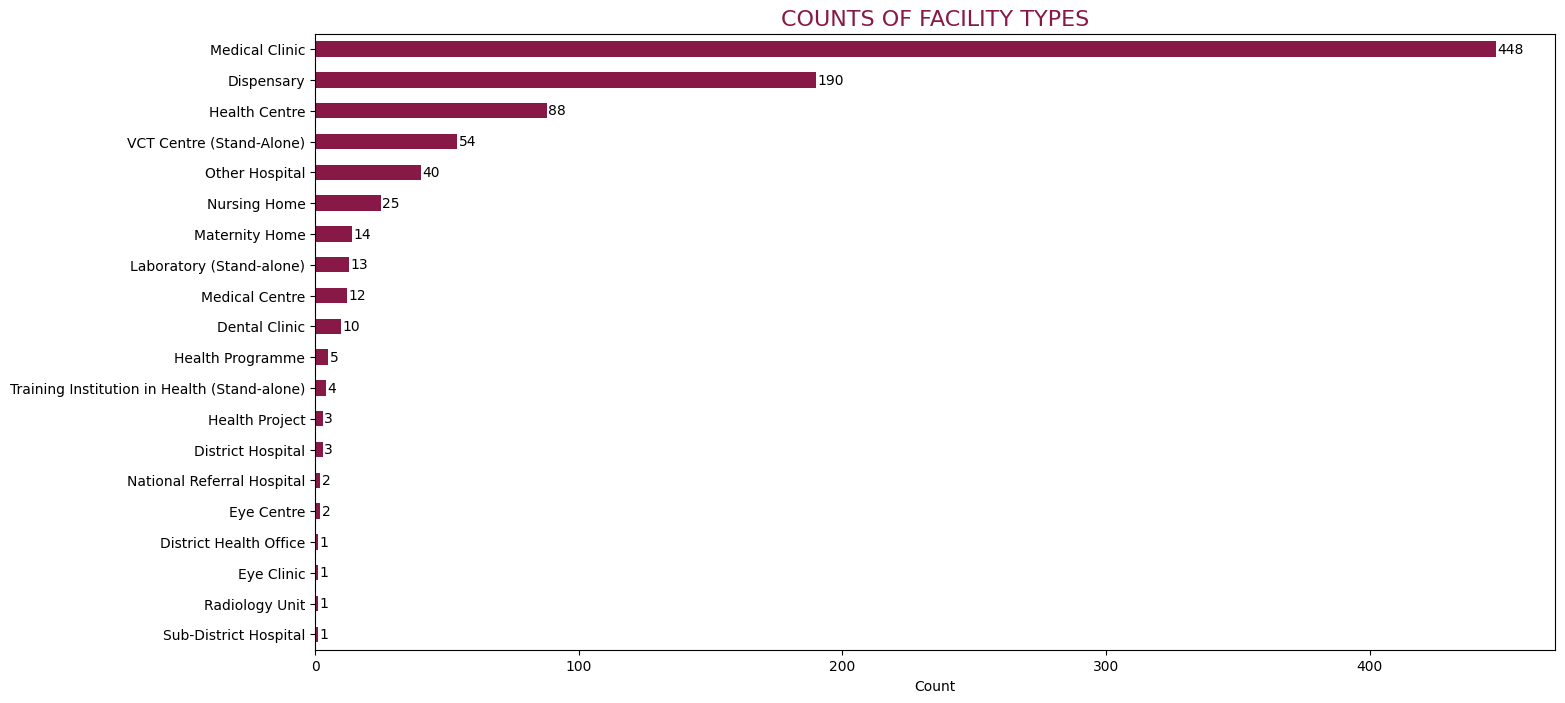

In [21]:
# Types (and number) of facilities available

type_counts = health_data['Type'].value_counts()

plt.figure(figsize=(16, 8))
ax = type_counts.plot(kind='barh', color=viz_colour)

for i, v in enumerate(type_counts):
    plt.text(v + 0.5, i, str(v), va='center')

plt.xlabel('Count')
plt.ylabel('')
plt.title('COUNTS OF FACILITY TYPES', fontsize=16, color=viz_colour)
plt.gca().invert_yaxis()
plt.savefig('chart2.png', bbox_inches='tight')
plt.show()

In [22]:
(448 + 190) / health_data.shape[0]

0.6957470010905126

Observation
- Medical clinics and dispensaries dominate the healthcare landscape in Nairobi, together accounting for about 70% of facilities.
- Higher-level institutions such as district and national referral hospitals are few.
- This indicates a strong emphasis on primary healthcare services and limited availability of specialised care.

#### - Combining the two datasets so as to calculate region-wise statistics

In [23]:
regions_data = pd.DataFrame()

regions_data['No. of Facilities'] = health_data['Region'].value_counts()
regions_data['IPD'] = health_data[health_data['IPD'] == 'Y'][['Region', 'IPD']].groupby('Region').count()
regions_data['Beds'] = health_data[['Region', 'Beds']].groupby('Region').sum()
regions_data['Cots'] = health_data[['Region', 'Cots']].groupby('Region').sum()


regions_data['C-IMCI'] = health_data[health_data['C-IMCI'] == 'Y'][['Region', 'C-IMCI']].groupby('Region').count()
regions_data['ART'] = health_data[health_data['ART'] == 'Y'][['Region', 'ART']].groupby('Region').count()
regions_data['FP'] = health_data[health_data['FP'] == 'Y'][['Region', 'FP']].groupby('Region').count()
regions_data['HBC'] = health_data[health_data['HBC'] == 'Y'][['Region', 'HBC']].groupby('Region').count()


regions_data['Population'] = sc_data.groupby('Region').sum()['Total'].to_frame()


In [24]:
# FACILITIES PER CAPITA - Helps identify underserved regions
regions_data['Facilities per 10k'] = regions_data['No. of Facilities']  / regions_data['Population'] * 10000
regions_data = regions_data.sort_values('Facilities per 10k', ascending=False)
regions_data

,No. of Facilities,IPD,Beds,Cots,C-IMCI,ART,FP,HBC,Population,Facilities per 10k
Region,,,,,,,,,,
Starehe,137,30,357.0,58.0,7.0,18,24,37,210423.0,6.510695
Kibra,81,20,1784.0,441.0,3.0,9,23,22,185777.0,4.360066
Langata,68,24,746.0,0.0,12.0,8,21,24,197489.0,3.44323
Makadara,51,25,195.0,19.0,3.0,9,22,13,189536.0,2.690782
Dagoretti,105,38,626.0,112.0,15.0,10,36,33,434208.0,2.418196
Westlands,71,17,633.0,32.0,7.0,7,15,14,308854.0,2.298821
Kamukunji,59,22,1083.0,206.0,9.0,10,21,14,268276.0,2.199228
Embakasi,145,55,729.0,142.0,9.0,12,54,34,988808.0,1.466412
Kasarani,184,52,403.0,56.0,7.0,21,51,46,1407138.0,1.307619


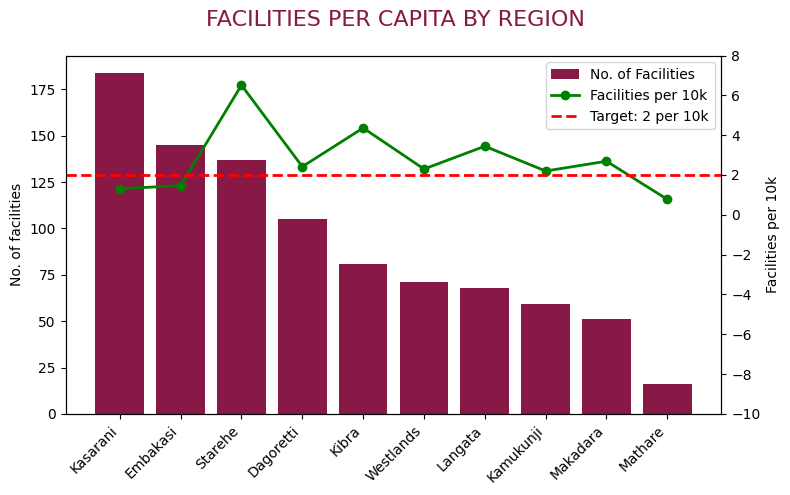

In [25]:
df = regions_data[['No. of Facilities', 'Facilities per 10k']]
df = df.sort_values('No. of Facilities', ascending=False).reset_index()

fig, ax1 = plt.subplots(figsize=(8, 5))

# plot the bars - primary axis
x = range(len(df))
ax1.bar(x, df["No. of Facilities"], color=viz_colour, label="No. of Facilities")
ax1.set_ylabel("No. of facilities")
ax1.tick_params(axis='y')

# secondary axis - line plot for Facilities per 10k
ax2 = ax1.twinx()
ax2.set_ylim(-10, 8)
ax2.plot(x, df["Facilities per 10k"], marker='o', color='green', label="Facilities per 10k", linewidth=2)
ax2.axhline(y=2, color='red', linestyle='--', linewidth=2, label="Target: 2 per 10k") # target per capita
ax2.set_ylabel("Facilities per 10k")

ax1.set_xticks(x)
ax1.set_xticklabels(df["Region"], rotation=45, ha='right')
fig.suptitle("FACILITIES PER CAPITA BY REGION", fontsize=16, color=viz_colour)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

plt.tight_layout()
plt.savefig('chart3.png', bbox_inches='tight')
plt.show()

Observation
- The bottom 3 (most underserved) regions are Mathare, Kasarani, and Embakasi all with less than 2 facilities per 10000 population.
- In order to bring this number to at least 2, we need the following number of facilities built.

In [26]:
facility_targets = regions_data.loc[regions_data.index[-3:], ['No. of Facilities', 'Population', 'Facilities per 10k']]
facility_targets['Target No. of Facilities'] = np.ceil(2 * facility_targets['Population'] / 10000)
facility_targets['New Facilities Required'] = np.ceil((2 - facility_targets['Facilities per 10k']) * facility_targets['Population'] / 10000)
facility_targets

,No. of Facilities,Population,Facilities per 10k,Target No. of Facilities,New Facilities Required
Region,,,,,
Embakasi,145,988808.0,1.466412,198,53
Kasarani,184,1407138.0,1.307619,282,98
Mathare,16,206564.0,0.774578,42,26


In [27]:
# Hospital Beds per capita
# Plot a bar with a line at 18 to show those below 18
np.floor((regions_data['Beds'] + regions_data['Cots']) / regions_data['Population'] * 10000)

,0
Region,
Starehe,19
Kibra,119
Langata,37
Makadara,11
Dagoretti,16
Westlands,21
Kamukunji,48
Embakasi,8
Kasarani,3


In [28]:
beds_targets = regions_data[['Beds', 'Cots', 'Population']]
beds_targets['Beds & Cots per 10k'] = np.floor((regions_data['Beds'] + regions_data['Cots']) / regions_data['Population'] * 10000)
beds_targets.sort_values('Beds & Cots per 10k', ascending=False)

/tmp/ipykernel_603/983506382.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  beds_targets['Beds & Cots per 10k'] = np.floor((regions_data['Beds'] + regions_data['Cots']) / regions_data['Population'] * 10000)


,Beds,Cots,Population,Beds & Cots per 10k
Region,,,,
Kibra,1784.0,441.0,185777.0,119
Kamukunji,1083.0,206.0,268276.0,48
Langata,746.0,0.0,197489.0,37
Mathare,730.0,0.0,206564.0,35
Westlands,633.0,32.0,308854.0,21
Starehe,357.0,58.0,210423.0,19
Dagoretti,626.0,112.0,434208.0,16
Makadara,195.0,19.0,189536.0,11
Embakasi,729.0,142.0,988808.0,8


Observation
- Those below the recommended threshold of 18 per 10,000 population are Dagoretti, Makadara, Embakasi, and Kasarani
- Also note that there are no cots in Mathare. So these are needed as well
- Now, let's calculate at least how many more beds are needed in each of the 4 regions and how manu cots are needed in Mathare

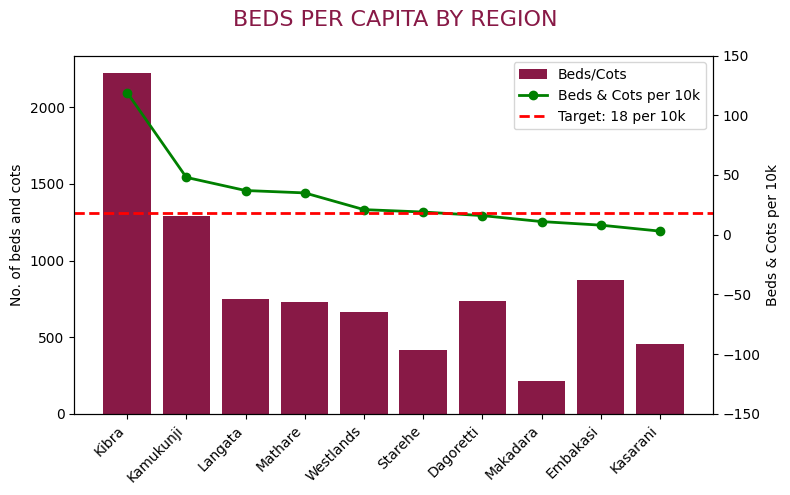

In [29]:
df = beds_targets.sort_values('Beds & Cots per 10k', ascending=False).reset_index()
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(x, df["Beds"]+df["Cots"], color=viz_colour, label="Beds/Cots")
ax1.set_ylabel("No. of beds and cots")
ax1.tick_params(axis='y')

ax2 = ax1.twinx()
ax2.set_ylim(-150, 150)
ax2.plot(x, df["Beds & Cots per 10k"], marker='o', color='green', label="Beds & Cots per 10k", linewidth=2)
ax2.axhline(y=18, color='red', linestyle='--', linewidth=2, label="Target: 18 per 10k")
ax2.set_ylabel("Beds & Cots per 10k")
y_max = max(df["Beds & Cots per 10k"].max(), 18)
ax1.set_xticks(range(len(df)))
ax1.set_xticklabels(df["Region"], rotation=45, ha='right')

fig.suptitle("BEDS PER CAPITA BY REGION", fontsize=16, color=viz_colour)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')
plt.tight_layout()
plt.savefig('chart4.png', bbox_inches='tight')
plt.show()

In [30]:
beds_targets = beds_targets[beds_targets['Beds & Cots per 10k'] < 18]
beds_targets['Target Beds/Cots'] = np.ceil(18 * beds_targets['Population'] / 10000)
beds_targets['Needed Beds/Cots'] = beds_targets['Target Beds/Cots'] - beds_targets['Beds'] - beds_targets['Cots']
beds_targets

,Beds,Cots,Population,Beds & Cots per 10k,Target Beds/Cots,Needed Beds/Cots
Region,,,,,,
Makadara,195.0,19.0,189536.0,11,342,128.0
Dagoretti,626.0,112.0,434208.0,16,782,44.0
Embakasi,729.0,142.0,988808.0,8,1780,909.0
Kasarani,403.0,56.0,1407138.0,3,2533,2074.0


In [31]:
# Add 53 Cots in Mathare
np.ceil(regions_data['Population']['Mathare'] *
            regions_data[regions_data.index != 'Mathare']['Cots'].sum() /
                regions_data[regions_data.index != 'Mathare']['Population'].sum())

np.float64(53.0)

In [32]:
# IPD and HBC facilities per capita
avg_ipd_pc = regions_data['IPD'].sum() / regions_data['Population'].sum() * 10000
avg_hbc_pc = regions_data['HBC'].sum() / regions_data['Population'].sum() * 10000
ipd_targets = regions_data[regions_data['IPD'] / regions_data['Population'] * 10000 < avg_ipd_pc][['Population', 'IPD', 'HBC']]

ipd_targets['IPD Target'] = np.ceil(avg_ipd_pc * ipd_targets['Population'] / 10000)
ipd_targets['HBC Target'] = np.ceil(avg_hbc_pc * ipd_targets['Population'] / 10000)

ipd_targets['New IPD Required'] = ipd_targets['IPD Target'] - ipd_targets['IPD']
ipd_targets['New HBC Required'] = ipd_targets['HBC Target'] - ipd_targets['HBC']

ipd_targets

,Population,IPD,HBC,IPD Target,HBC Target,New IPD Required,New HBC Required
Region,,,,,,,
Westlands,308854.0,17,14,21,18,4,4
Embakasi,988808.0,55,34,65,56,10,22
Kasarani,1407138.0,52,46,93,79,41,33
Mathare,206564.0,5,8,14,12,9,4


<span style="color:gray">

### End of SDG 3.8

<span style="color:orange">

### SDG Target 3.2 - Neonatal & Child Mortality

Under this, we'll look at facilities that offer `Community Integrated Management of Childhood Illness (C-IMCI)` services.

In [33]:
avg_imci_pc = regions_data['C-IMCI'].sum() / regions_data['Population'].sum() * 10000
imci_targets = regions_data[regions_data['C-IMCI'] / regions_data['Population'] * 10000 < avg_imci_pc][['Population', 'C-IMCI']]
imci_targets['C-IMCI Target'] = np.ceil(avg_imci_pc * imci_targets['Population'] / 10000)
imci_targets['New C-IMCI Required'] = imci_targets['C-IMCI Target'] - imci_targets['C-IMCI']

imci_targets

,Population,C-IMCI,C-IMCI Target,New C-IMCI Required
Region,,,,
Kibra,185777.0,3.0,4,1.0
Makadara,189536.0,3.0,4,1.0
Embakasi,988808.0,9.0,17,8.0
Kasarani,1407138.0,7.0,24,17.0


- All countries aim to reduce neonatal mortality to at least as low as 12 per 1,000 live births and under-5 mortality to at least as low as 25 per 1,000 live births

<span style="color:gray">

### End of SDG 3.2

<span style="color:orange">

### SDG Target 3.3 - Fight Communicable Diseases

In [34]:
avg_art_pc = regions_data['ART'].sum() / regions_data['Population'].sum() * 10000
art_targets = regions_data[regions_data['ART'] / regions_data['Population'] * 10000 < avg_art_pc][['Population', 'ART']]
art_targets['ART Target'] = np.ceil(avg_art_pc * art_targets['Population'] / 10000)
art_targets['New ART Required'] = art_targets['ART Target'] - art_targets['ART']

art_targets

,Population,ART,ART Target,New ART Required
Region,,,,
Dagoretti,434208.0,10,11,1
Westlands,308854.0,7,8,1
Embakasi,988808.0,12,25,13
Kasarani,1407138.0,21,35,14
Mathare,206564.0,5,6,1


- By 2030, end the epidemics of AIDS, tuberculosis, malaria and neglected tropical diseases and combat hepatitis, water-borne diseases and other communicable diseases

<span style="color:gray">

### End of SDG 3.3

<span style="color:orange">

### SDG Target 3.7 - Sexual and Reproductive Health

In [35]:
avg_fp_pc = regions_data['FP'].sum() / regions_data['Population'].sum() * 10000
fp_targets = regions_data[regions_data['FP'] / regions_data['Population'] * 10000 < avg_fp_pc][['Population', 'FP']]
fp_targets['FP Target'] = np.ceil(avg_fp_pc * fp_targets['Population'] / 10000)
fp_targets['New FP Required'] = fp_targets['FP Target'] - fp_targets['FP']

fp_targets

,Population,FP,FP Target,New FP Required
Region,,,,
Westlands,308854.0,15,20,5
Embakasi,988808.0,54,62,8
Kasarani,1407138.0,51,88,37
Mathare,206564.0,5,13,8


- By 2030, ensure universal access to sexual and reproductive health-care services, including for family planning, information and education, and the integration of reproductive health into national strategies and programmes.

### REFERENCES AND DATA SOURCES
- https://open.africa/dataset/health-facilities-in-kenya
- https://open.africa/dataset/2019-kenya-population-and-housing-census
- https://data.unicef.org/sdgs/goal-3-good-health-wellbeing/
- https://www.globalgoals.org/goals/3-good-health-and-well-being/
- https://www.who.int/europe/about-us/our-work/sustainable-development-goals/targets-of-sustainable-development-goal-3
- https://en.wikipedia.org/wiki/Roysambu_Constituency
- https://en.wikipedia.org/wiki/Ruaraka_Constituency
- https://en.wikipedia.org/wiki/Kasarani_Constituency
- https://en.wikipedia.org/wiki/Njiru,_Nairobi